# PentaByte — Unit 04: Connectionist AI: Learning, Testing, and Applications

**Executable companion notebook** to `PentaByte_Unit_04_Detailed_Markdown_V2.md`.  
**Chapters:** Chapters 13–16.  
**Scope:** Loss functions, training intuition, Iris MLP, validation, held-out evaluation, and ethical context.

This notebook reuses the Python examples from the detailed lesson. Read the Markdown guide for concepts, diagrams, and full explanations. Run the code cells in order from top to bottom using **Run All**.

## Chapter 13 — Prediction Error and Loss Functions

**13.2 — Introduce loss as a numerical measure of prediction error**

Run the cell below, inspect its output, and compare it with the corresponding lesson in the Markdown document.

In [1]:
# Illustrative one-output example; NOT the Iris MLP loss.
target = 1.0
predictions = [0.8, 0.6]

for prediction in predictions:
    squared_error = (target - prediction) ** 2
    print(f"Prediction: {prediction:.1f}; squared error: {squared_error:.2f}")

Prediction: 0.8; squared error: 0.04
Prediction: 0.6; squared error: 0.16


## Chapter 15 — Training a Simple Neural Network Classifier

**15.1 — Open a prepared Iris notebook, create training and held-out test data, and scale features correctly**

Run the cell below, inspect its output, and compare it with the corresponding lesson in the Markdown document.

In [2]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

iris = load_iris()
X = iris.data             # Four measurements per flower
Y = iris.target           # Correct species indices (0, 1, 2)
class_names = iris.target_names

X_train, X_test, y_train, y_test = train_test_split(
    X, Y,
    test_size=0.20,
    random_state=42,
    stratify=Y,
)

print("Feature names:", list(iris.feature_names))
print("Class names:", list(class_names))
print("Training samples:", len(X_train))
print("Held-out test samples:", len(X_test))

Feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Class names: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]
Training samples: 120
Held-out test samples: 30


**15.2 — Run a supplied multilayer perceptron classifier and observe training**

Run the cell below, inspect its output, and compare it with the corresponding lesson in the Markdown document.

In [3]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier

model = make_pipeline(
    StandardScaler(),
    MLPClassifier(
        hidden_layer_sizes=(8,),
        activation="relu",
        solver="adam",
        learning_rate_init=0.01,
        alpha=0.01,
        max_iter=1200,
        random_state=42,
    ),
)

# Fit ONLY on training examples. Do not evaluate X_test yet.
model.fit(X_train, y_train)
print("Model training complete.")

Model training complete.


**15.2 — Run a supplied multilayer perceptron classifier and observe training**

Run the cell below, inspect its output, and compare it with the corresponding lesson in the Markdown document.

In [4]:
network = model.named_steps["mlpclassifier"]

print("Training accuracy:", round(model.score(X_train, y_train), 3))
print("Epochs completed:", network.n_iter_)
print("First recorded loss:", round(network.loss_curve_[0], 4))
print("Last recorded loss:", round(network.loss_curve_[-1], 4))

Training accuracy: 0.983
Epochs completed: 288
First recorded loss: 1.1974
Last recorded loss: 0.0451


**15.2 — Run a supplied multilayer perceptron classifier and observe training**

Run the cell below, inspect its output, and compare it with the corresponding lesson in the Markdown document.

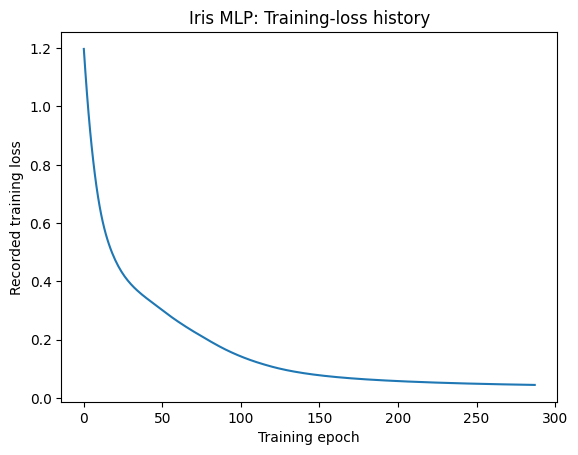

In [5]:
import matplotlib.pyplot as plt

plt.plot(network.loss_curve_)
plt.xlabel("Training epoch")
plt.ylabel("Recorded training loss")
plt.title("Iris MLP: Training-loss history")
plt.show()

**15.3 — Change one permitted setting in a guided copy; compare using validation data only**

Run the cell below, inspect its output, and compare it with the corresponding lesson in the Markdown document.

In [6]:
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train,
    test_size=0.25,
    random_state=42,
    stratify=y_train,
)

for neurons in [8, 12]:
    candidate = make_pipeline(
        StandardScaler(),
        MLPClassifier(
            hidden_layer_sizes=(neurons,),  # Only setting changed
            activation="relu",
            solver="adam",
            learning_rate_init=0.01,
            alpha=0.01,
            max_iter=1200,
            random_state=42,
        ),
    )
    candidate.fit(X_fit, y_fit)

    validation_accuracy = candidate.score(X_val, y_val)
    last_loss = candidate.named_steps["mlpclassifier"].loss_curve_[-1]
    print(
        f"Hidden neurons: {neurons}; "
        f"validation accuracy: {validation_accuracy:.3f}; "
        f"last training loss: {last_loss:.4f}"
    )

Hidden neurons: 8; validation accuracy: 0.933; last training loss: 0.0439
Hidden neurons: 12; validation accuracy: 0.933; last training loss: 0.0440


## Chapter 16 — Evaluating and Using Neural Networks Responsibly

**16.1 — Evaluate held-out predictions using accuracy, a confusion matrix, and a majority-class baseline**

Run the cell below, inspect its output, and compare it with the corresponding lesson in the Markdown document.

In [7]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

# Final held-out predictions: do not use these to tune the model.
y_pred = model.predict(X_test)
held_out_accuracy = accuracy_score(y_test, y_pred)

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)
baseline_accuracy = accuracy_score(y_test, baseline_pred)

print("Training accuracy:", round(model.score(X_train, y_train), 3))
print("Held-out accuracy:", round(held_out_accuracy, 3))
print("Majority-class baseline:", round(baseline_accuracy, 3))
print("Class order:", list(class_names))
print("Confusion matrix (actual rows, predicted columns):")
print(confusion_matrix(y_test, y_pred, labels=[0, 1, 2]))

Training accuracy: 0.983
Held-out accuracy: 0.967
Majority-class baseline: 0.333
Class order: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]
Confusion matrix (actual rows, predicted columns):
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]


**16.1 — Evaluate held-out predictions using accuracy, a confusion matrix, and a majority-class baseline**

Run the cell below, inspect its output, and compare it with the corresponding lesson in the Markdown document.

In [8]:
mistake_indices = [
    i for i, (actual, predicted) in enumerate(zip(y_test, y_pred))
    if actual != predicted
]

if mistake_indices:
    i = mistake_indices[0]
    print("Test-set position:", i)
    print("Measurements:", X_test[i].tolist())
    print("Actual:", class_names[y_test[i]])
    print("Predicted:", class_names[y_pred[i]])
else:
    print("No mistakes in this held-out split.")

Test-set position: 25
Measurements: [6.7, 3.0, 5.0, 1.7]
Actual: versicolor
Predicted: virginica


## Try it yourself

1. Compare squared errors for predictions 0.8 and 0.6 when target is 1.
2. Read the loss curve and compare the first and last training losses.
3. Explain why the validation comparison uses only the training partition.
4. Explain what held-out accuracy and the confusion matrix mean.

**Important:** Never use held-out test scores to choose hyperparameters. This training notebook is an educational demonstration, not a certified real-world classifier.

---
**PentaByte quality notes:** Code blocks are copied from the Unit Markdown and intended to run sequentially. Use the source document for each learning objective, pseudocode, activities, and reference context.
